In [468]:
import numpy as np
import json
import re
from konlpy.tag import Okt
from kiwipiepy import Kiwi
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc
from wordcloud import WordCloud
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import numpy as np
import matplotlib
import warnings
warnings.filterwarnings(action='ignore')
import folium
import seaborn as sns
import requests
from bs4 import BeautifulSoup
import time
from googlesearch import search

In [469]:
import re
from collections import Counter
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from wordcloud import WordCloud
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties( fname = font_path).get_name()
matplotlib.rc('font', family = font_name)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

import matplotlib.pyplot as plt
import seaborn as sns
import ast

In [470]:
df = pd.read_csv('./data/ch02_english_score_raw.csv')

In [471]:
df

,student_id,classroom,score_raw
0,20260110,B,78.2
1,20260162,C,82.3
2,20260124,C,76.1
3,20260225,B,68.4
4,20260087,A,80.3
...,...,...,...
183,20260213,A,74.1
184,20260128,C,999
185,20260017,A,70.0점
186,20260209,A,71.4


In [472]:
df['score_clean'] = (
    df['score_raw']
    .astype(str)
    .str.extract(r'(\d+(?:\.\d+)?)')[0]
    .astype(float)
)

In [473]:
df.loc[df['score_clean'] > 100, 'score_clean'] = None

In [474]:
df_m = df.sort_values(by=['student_id','score_clean'])

In [475]:
df_m

,student_id,classroom,score_raw,score_clean
64,20260002,A,81.6,81.6
115,20260004,C,83.5,83.5
77,20260005,A,84.5,84.5
52,20260007,C,87.3,87.3
50,20260007,C,결시,NaN
...,...,...,...,...
86,20260244,C,89.7,89.7
111,20260246,A,71.5,71.5
14,20260247,A,80.5,80.5
153,20260249,B,63.1,63.1


In [476]:
df_m = df_m.drop(df_m[df_m['score_clean'] < 10].index)

In [477]:
df_m = df.drop_duplicates(subset=['student_id'], keep='first')

In [478]:
df_m = df_m[df_m['score_clean'] >= 10]

In [479]:
df_m

,student_id,classroom,score_raw,score_clean
0,20260110,B,78.2,78.2
1,20260162,C,82.3,82.3
2,20260124,C,76.1,76.1
3,20260225,B,68.4,68.4
4,20260087,A,80.3,80.3
...,...,...,...,...
168,20260107,A,77.8,77.8
169,20260193,B,52.9,52.9
171,20260181,A,72.1,72.1
174,20260026,B,69.9,69.9


In [480]:
freq, _ = np.histogram(df_m['score_clean'], bins=10, range=(0, 100))
freq

array([ 0,  0,  0,  0,  0,  9, 21, 42, 38, 10])

In [481]:
freq, bin_edges = np.histogram(df_m['score_clean'].dropna(), bins=10, range=(0, 100))

freq_class = [f"{int(bin_edges[i])}~{int(bin_edges[i+1])}" for i in range(len(bin_edges)-1)]


freq_df = pd.DataFrame(
    {'frequency': freq},
    index=pd.Index(freq_class, name='class')
)

In [482]:
freq_df

,frequency
class,
0~10,0
10~20,0
20~30,0
30~40,0
40~50,0
50~60,9
60~70,21
70~80,42
80~90,38


In [483]:
#상대도수
rel_freq = freq / freq.sum()
rel_freq

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.075     , 0.175     , 0.35      , 0.31666667, 0.08333333])

In [484]:
#누적상대도수
cum_rel_freq = np.cumsum(rel_freq)
cum_rel_freq

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.075     , 0.25      , 0.6       , 0.91666667, 1.        ])

In [485]:
class_marks = (bin_edges[:-1] + bin_edges[1:]) / 2

In [486]:
freq_df['class value'] = class_marks
freq_df['relative frequency'] = rel_freq
freq_df['cumulative relative frequency'] = cum_rel_freq

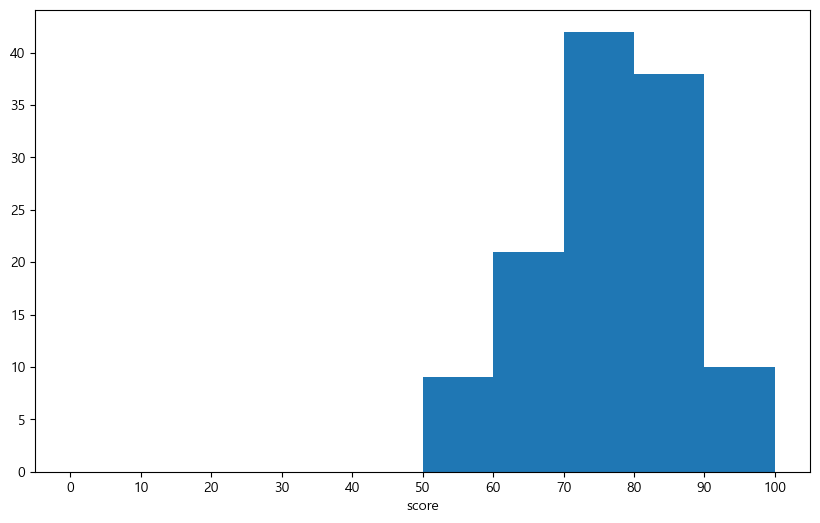

In [487]:
#히스토그램 그리기
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)
freq, _, _ = ax.hist(df_m['score_clean'], bins=10, range=(0, 100))
ax.set_xlabel('score')
ax.set_xticks(np.linspace(0, 100, 10+1))
plt.show()

#최소가 51점인것을 확인했기에 50~ 100점 사이에 그래프가 그러져있으며 70~80이 제일많고
#그다음이 80~90이다.

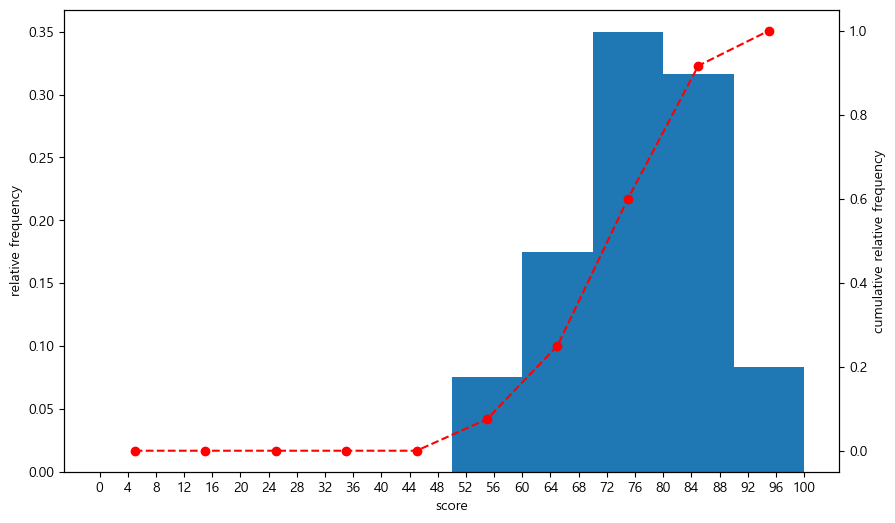

In [488]:
fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(111)
ax2 = ax1.twinx()


weights = np.ones_like(df_m['score_clean']) / len(df_m['score_clean'])
rel_freq, _, _ = ax1.hist(df_m['score_clean'], bins=10,
                          range=(0, 100), weights=weights)

cum_rel_freq = np.cumsum(rel_freq)
class_value = [(i+(i+10))//2 for i in range(0, 100, 10)]
# 꺾은선 그래프를 그림
# 인수 ls를 '--'로 하면 점선이 그려짐
# 인수 marker를 'o'으로 하면 데이터 점을 그람
# 인수 color를 'gray'로 하면 회색으로 지정
ax2.plot(class_value, cum_rel_freq,
         ls='--', marker='o', color='red')
# 꺾은선 그래프의 눈금선을 제거
ax2.grid(visible=False)

ax1.set_xlabel('score')
ax1.set_ylabel('relative frequency')
ax2.set_ylabel('cumulative relative frequency')
ax1.set_xticks(np.linspace(0, 100, 25+1))

plt.show()

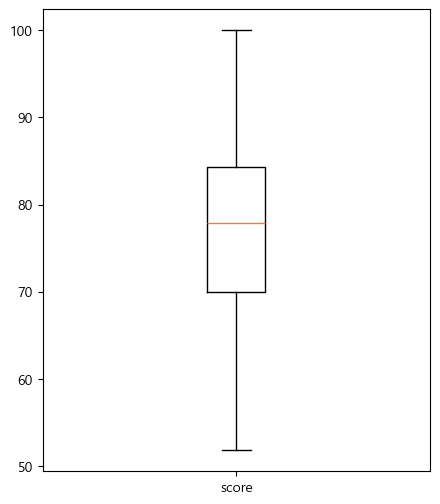

In [489]:
fig = plt.figure(figsize=(5, 6))
ax = fig.add_subplot(111)
ax.boxplot(df_m['score_clean'].dropna(), labels=['score'])

plt.show()

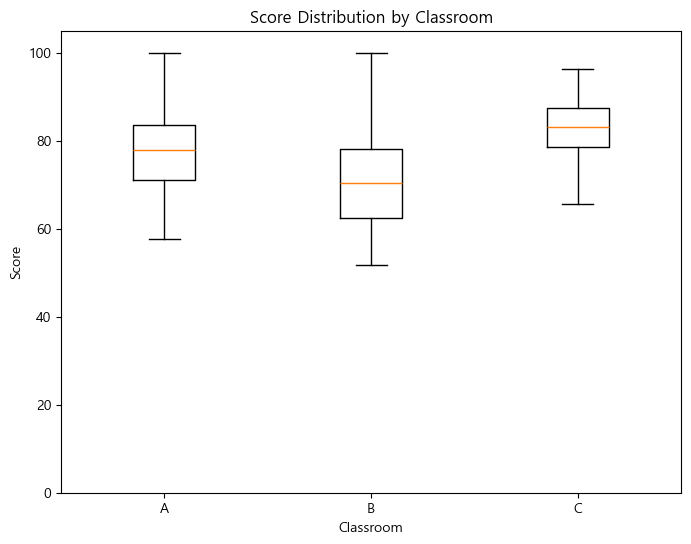

In [490]:
#반별로 나누어서 박스플롯
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111)

score_a = df_m[df_m['classroom'] == 'A']['score_clean'].dropna()
score_b = df_m[df_m['classroom'] == 'B']['score_clean'].dropna()
score_c = df_m[df_m['classroom'] == 'C']['score_clean'].dropna()

ax.boxplot([score_a, score_b, score_c], labels=['A', 'B', 'C'])

ax.set_xlabel('Classroom')
ax.set_ylabel('Score')
#100점이 최대라 조금 올림
ax.set_ylim(0, 105)
ax.set_title('Score Distribution by Classroom')

plt.show()
#c반을 제외하고는 최대가 100점이고 최소는 b반이 조금 낮다.
#c반은 제일 높은것이 적은대신 대체로 평균이 높은 편이다.

In [491]:
q1 = df_m['score_clean'].quantile(0.25)
q3 = df_m['score_clean'].quantile(0.75)
iqr = q3 - q1
iqr

np.float64(14.325000000000003)

In [492]:
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)
upper_bound

np.float64(105.7875)

In [493]:
lower_bound

np.float64(48.48749999999999)

In [494]:
df_m[(df_m['score_clean'] < lower_bound) | (df_m['score_clean'] > upper_bound)]['score_clean']

Series([], Name: score_clean, dtype: float64)

In [495]:
def get_outlier_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - (1.5 * iqr)
    upper_bound = q3 + (1.5 * iqr)
    
    return pd.Series({
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Lower_Bound': lower_bound,
        'Upper_Bound': upper_bound
    })

# 반(classroom)별 적용
bounds_df = df_m.groupby('classroom')['score_clean'].apply(get_outlier_bounds).unstack()

print(bounds_df)

              Q1      Q3     IQR  Lower_Bound  Upper_Bound
classroom                                                 
A          71.05  83.550  12.500      52.3000     102.3000
B          62.35  78.100  15.750      38.7250     101.7250
C          78.65  87.425   8.775      65.4875     100.5875


In [496]:
df_c = df_m[df_m['classroom'] == 'C']

q1 = df_c['score_clean'].quantile(0.25)
q3 = df_c['score_clean'].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

c_outliers = df_c[(df_c['score_clean'] < lower_bound) | (df_c['score_clean'] > upper_bound)]['score_clean']

print(c_outliers)

Series([], Name: score_clean, dtype: float64)


In [497]:
df = pd.read_csv('./data/ch03_raw_big_orders.csv')

In [498]:
len(df)

4000

In [499]:
#1번 날짜 여러 포맷 허용
df['clean_time']=pd.to_datetime(df['order_time'],format='mixed', utc=True)

In [500]:
df['clean_time']

0      2026-01-05 06:00:00+00:00
1      2026-01-18 18:00:00+00:00
2      2026-01-11 21:00:00+00:00
3      2026-01-05 01:00:00+00:00
4      2026-01-03 14:00:00+00:00
                  ...           
3995   2026-01-06 11:00:00+00:00
3996   2026-01-04 02:00:00+00:00
3997   2026-01-17 05:00:00+00:00
3998                         NaT
3999   2026-01-05 03:00:00+00:00
Name: clean_time, Length: 4000, dtype: datetime64[ns, UTC]

In [501]:
#번 금액
df['clean_amount'] = (
    df['amount']
    .astype(str)
    .str.replace(',', '', regex=False)
    .str.extract(r'(\d+(?:\.\d+)?)')[0]
    .astype(float)
)

In [502]:
df

,order_id,order_time,platform,amount,status,clean_time,clean_amount
0,O100000,2026/01/05 06:00 AM,네이버페이,"-₩33,000(환불)",refund,2026-01-05 06:00:00+00:00,33000.0
1,O100001,2026-01-19 03:00:00+09:00,쿠팡,"₩12,900",paid,2026-01-18 18:00:00+00:00,12900.0
2,O100002,2026-01-12 06:00:00+09:00,기타,"-₩12,900",cancel,2026-01-11 21:00:00+00:00,12900.0
3,O100003,2026-01-05 10:00:00+09:00,쿠팡,"₩45,000",paid,2026-01-05 01:00:00+00:00,45000.0
4,O100004,2026-01-03 23:00:00+09:00,쿠팡,"-₩12,900(환불)",refund,2026-01-03 14:00:00+00:00,12900.0
...,...,...,...,...,...,...,...
3995,O103995,2026/01/06 11:00 AM,쿠팡,"-₩19,800(환불)",refund,2026-01-06 11:00:00+00:00,19800.0
3996,O103996,2026-01-04 11:00:00+09:00,Npay,"₩45,000",paid,2026-01-04 02:00:00+00:00,45000.0
3997,O103997,2026-01-17 14:00:00+09:00,쿠팡,"₩19,800",paid,2026-01-17 05:00:00+00:00,19800.0
3998,O103998,NaN,네이버페이,8900원,paid,NaT,8900.0


In [503]:
a = df[df['status'].isin(['refund', 'cancel'])]['clean_amount'].sum()
b = df[~df['status'].isin(['refund', 'cancel'])]['clean_amount'].sum()
c = b-a
c

np.float64(76838700.0)

In [504]:
df['platform'].value_counts()

platform
Npay       930
네이버페이      924
coupang    881
쿠팡         880
기타         385
Name: count, dtype: int64

In [505]:
#4번 쿠팡/네이버페이
df.loc[df['platform'] == 'Npay', 'platform'] = '네이버페이'
df.loc[df['platform'] == 'coupang', 'platform'] = '쿠팡'

In [506]:
df['platform'].value_counts()

platform
네이버페이    1854
쿠팡       1761
기타        385
Name: count, dtype: int64

In [507]:
df = df.sort_values(by=['order_id'])

In [508]:
df_m = df.drop_duplicates(subset=['order_id'], keep='first')

In [509]:
df_m.head()

,order_id,order_time,platform,amount,status,clean_time,clean_amount
0,O100000,2026/01/05 06:00 AM,네이버페이,"-₩33,000(환불)",refund,2026-01-05 06:00:00+00:00,33000.0
1,O100001,2026-01-19 03:00:00+09:00,쿠팡,"₩12,900",paid,2026-01-18 18:00:00+00:00,12900.0
2,O100002,2026-01-12 06:00:00+09:00,기타,"-₩12,900",cancel,2026-01-11 21:00:00+00:00,12900.0
3,O100003,2026-01-05 10:00:00+09:00,쿠팡,"₩45,000",paid,2026-01-05 01:00:00+00:00,45000.0
4,O100004,2026-01-03 23:00:00+09:00,쿠팡,"-₩12,900(환불)",refund,2026-01-03 14:00:00+00:00,12900.0


In [510]:
df['day_name'] = df['clean_time'].dt.day_name(locale='ko_KR')
df['hour'] = df['clean_time'].dt.hour

In [511]:
df.head()

,order_id,order_time,platform,amount,status,clean_time,clean_amount,day_name,hour
0,O100000,2026/01/05 06:00 AM,네이버페이,"-₩33,000(환불)",refund,2026-01-05 06:00:00+00:00,33000.0,월요일,6.0
1,O100001,2026-01-19 03:00:00+09:00,쿠팡,"₩12,900",paid,2026-01-18 18:00:00+00:00,12900.0,일요일,18.0
2,O100002,2026-01-12 06:00:00+09:00,기타,"-₩12,900",cancel,2026-01-11 21:00:00+00:00,12900.0,일요일,21.0
3,O100003,2026-01-05 10:00:00+09:00,쿠팡,"₩45,000",paid,2026-01-05 01:00:00+00:00,45000.0,월요일,1.0
4,O100004,2026-01-03 23:00:00+09:00,쿠팡,"-₩12,900(환불)",refund,2026-01-03 14:00:00+00:00,12900.0,토요일,14.0


In [512]:
df_time = df[['day_name','hour','clean_time']].dropna()
df_time['day_num'] = df_time['clean_time'].dt.dayofweek

In [513]:
df_time

,day_name,hour,clean_time,day_num
0,월요일,6.0,2026-01-05 06:00:00+00:00,0
1,일요일,18.0,2026-01-18 18:00:00+00:00,6
2,일요일,21.0,2026-01-11 21:00:00+00:00,6
3,월요일,1.0,2026-01-05 01:00:00+00:00,0
4,토요일,14.0,2026-01-03 14:00:00+00:00,5
...,...,...,...,...
3994,월요일,20.0,2026-01-19 20:00:00+00:00,0
3995,화요일,11.0,2026-01-06 11:00:00+00:00,1
3996,일요일,2.0,2026-01-04 02:00:00+00:00,6
3997,토요일,5.0,2026-01-17 05:00:00+00:00,5


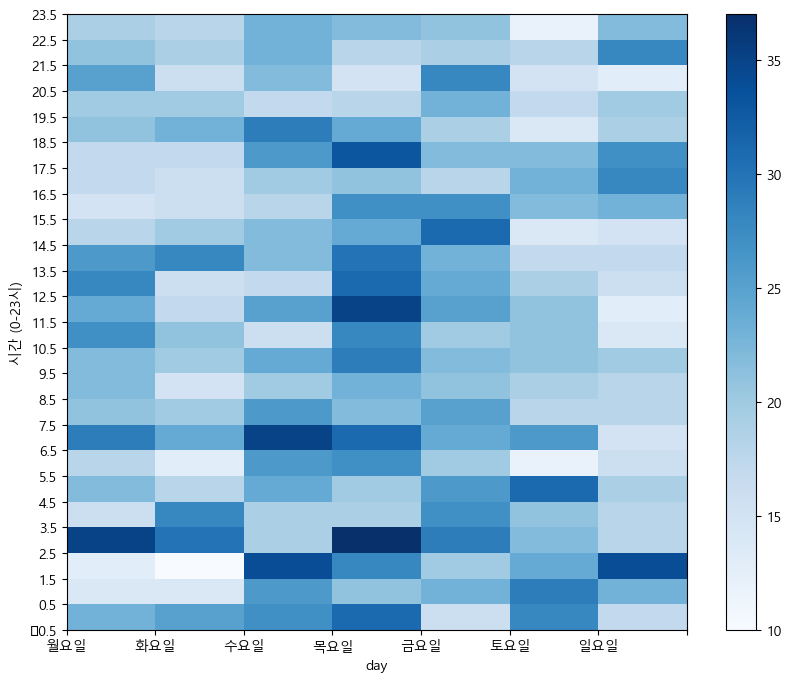

In [514]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111)

c = ax.hist2d(
    df_time['day_num'], 
    df_time['hour'],
    bins=[7, 24],
    range=[[-0.5, 6.5], [-0.5, 23.5]], 
    cmap='Blues'
)
ax.set_xlabel('day')
ax.set_ylabel('hour')
ax.set_xticklabels(['월요일', '화요일', '수요일', '목요일', '금요일', '토요일', '일요일'])
ax.set_xticks(c[1])
ax.set_yticks(c[2])
ax.set_ylabel('시간 (0-23시)')
# 컬러 바의 표시
fig.colorbar(c[3], ax=ax)
plt.show()

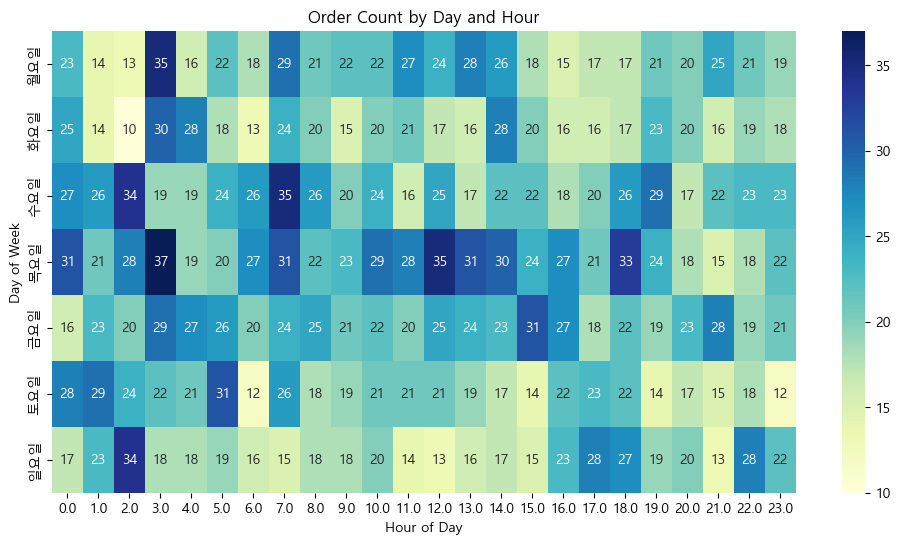

In [515]:
pivot_data = pd.crosstab(index=df['day_name'], columns=df['hour'])


day_order = ['월요일', '화요일', '수요일', '목요일', '금요일', '토요일', '일요일']

pivot_data = pivot_data.reindex([d for d in day_order if d in pivot_data.index])

plt.figure(figsize=(12, 6))
sns.heatmap(pivot_data, cmap='YlGnBu', annot=True, fmt='d', cbar=True)

plt.title('Order Count by Day and Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')

plt.show()

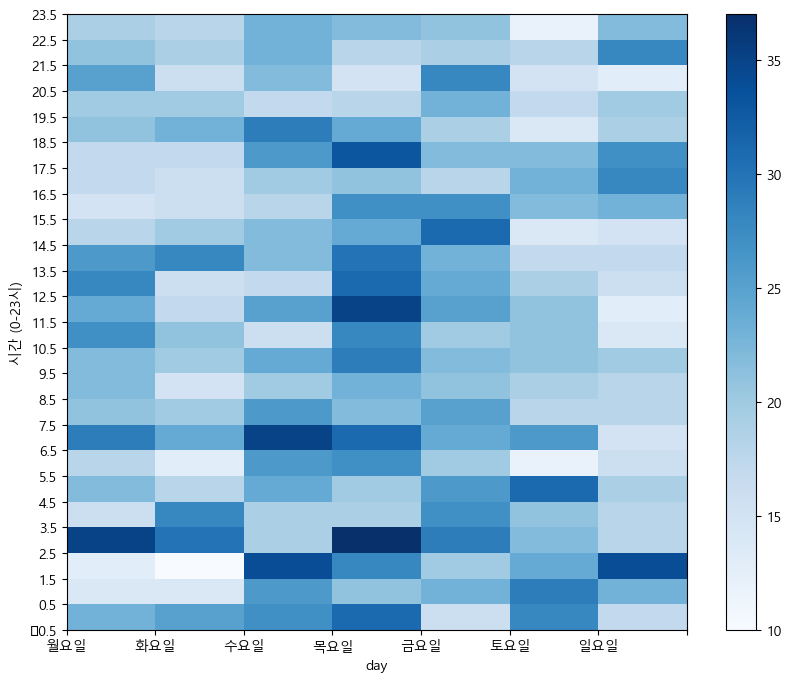

In [516]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111)

c = ax.hist2d(
    df_time['day_num'], 
    df_time['hour'],
    bins=[7, 24],
    range=[[-0.5, 6.5], [-0.5, 23.5]], 
    cmap='Blues'
)
ax.set_xlabel('day')
ax.set_ylabel('hour')
ax.set_xticklabels(['월요일', '화요일', '수요일', '목요일', '금요일', '토요일', '일요일'])
ax.set_xticks(c[1])
ax.set_yticks(c[2])
ax.set_ylabel('시간 (0-23시)')
# 컬러 바의 표시
fig.colorbar(c[3], ax=ax)
plt.show()

In [517]:
df_n = df.loc[df['platform']=='네이버페이'].dropna()
df_c = df.loc[df['platform']=='쿠팡'].dropna()

In [518]:
df_n['day_num'] = df_n['clean_time'].dt.dayofweek
df_c['day_num'] = df_c['clean_time'].dt.dayofweek

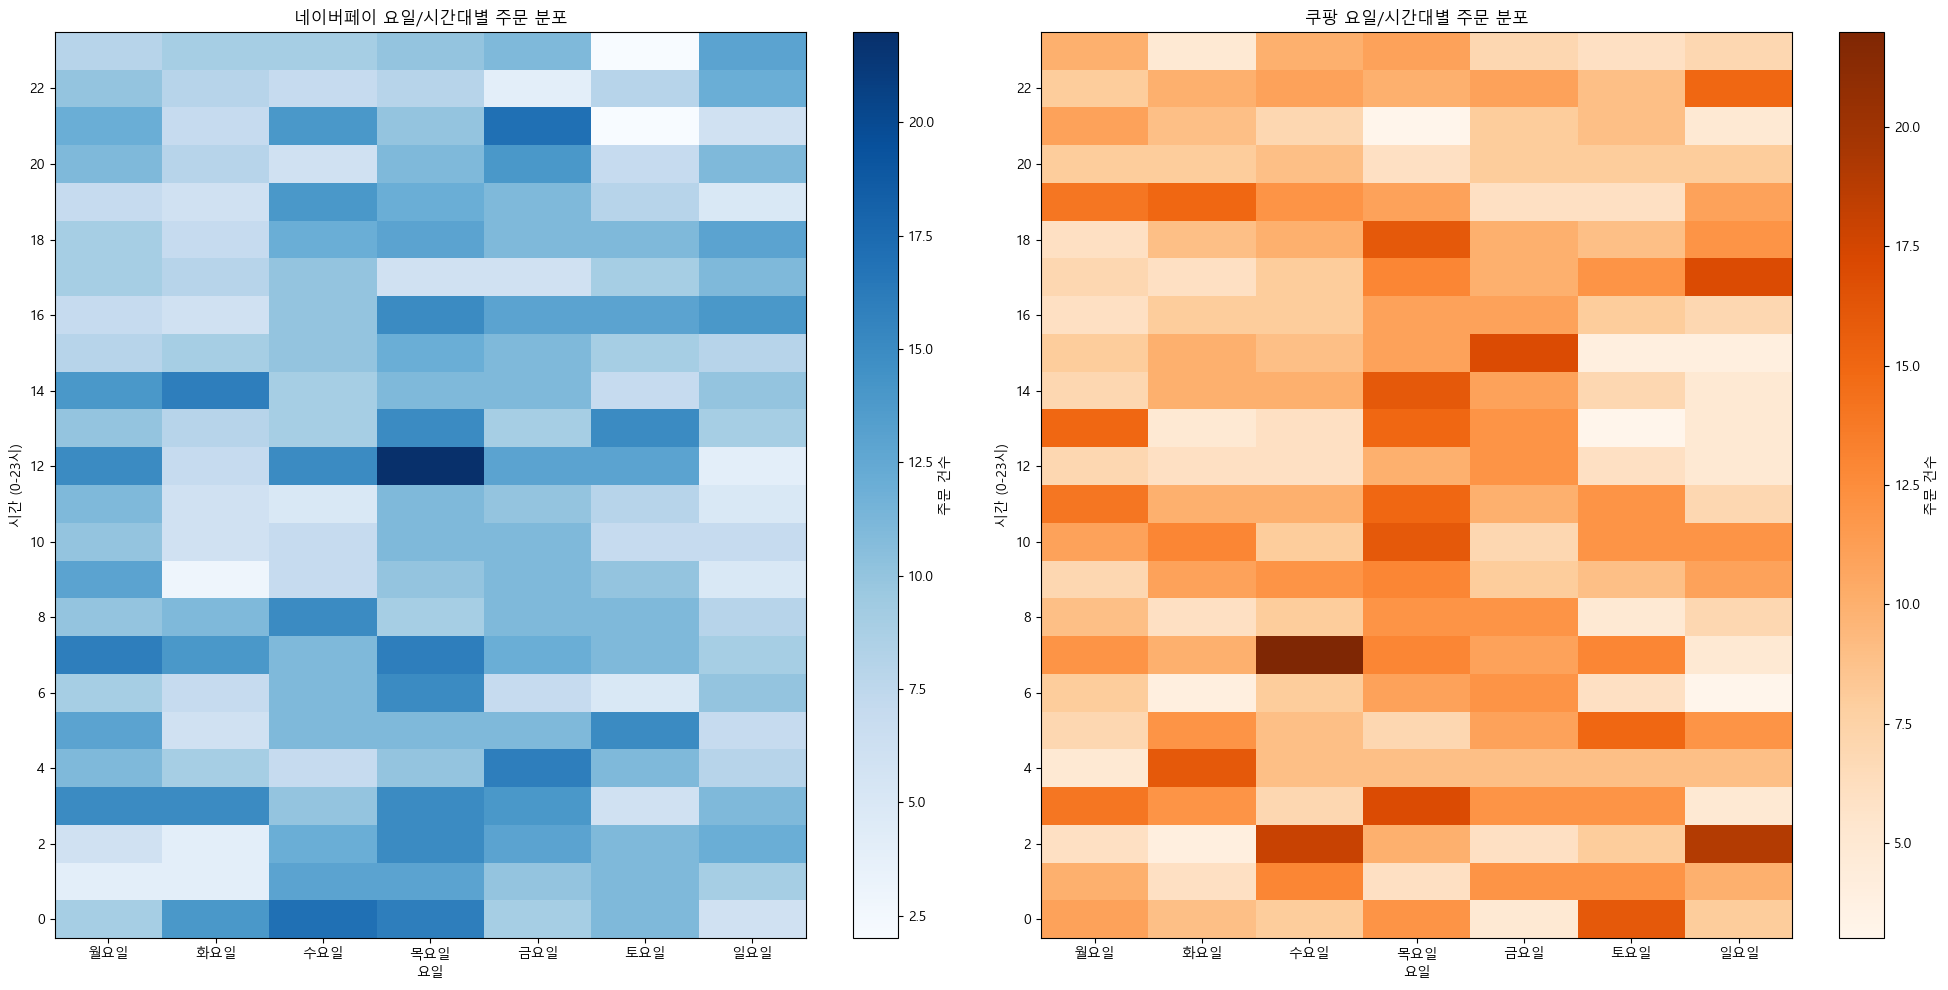

In [519]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

days = ['월요일', '화요일', '수요일', '목요일', '금요일', '토요일', '일요일']

c1 = ax1.hist2d(
    df_n['day_num'], 
    df_n['hour'],
    bins=[7, 24],
    range=[[-0.5, 6.5], [-0.5, 23.5]], 
    cmap='Blues'
)
ax1.set_title('네이버페이 요일/시간대별 주문 분포')
ax1.set_xlabel('요일')
ax1.set_ylabel('시간 (0-23시)')
ax1.set_xticks(range(7))
ax1.set_xticklabels(days)
ax1.set_yticks(range(0, 24, 2))
fig.colorbar(c1[3], ax=ax1, label='주문 건수')

c2 = ax2.hist2d(
    df_c['day_num'], 
    df_c['hour'],
    bins=[7, 24],
    range=[[-0.5, 6.5], [-0.5, 23.5]], 
    cmap='Oranges'  # 쿠팡은 주황색 계열로 구분을 주면 더욱 좋습니다!
)
ax2.set_title('쿠팡 요일/시간대별 주문 분포')
ax2.set_xlabel('요일')
ax2.set_ylabel('시간 (0-23시)')
ax2.set_xticks(range(7))
ax2.set_xticklabels(days)
ax2.set_yticks(range(0, 24, 2))
fig.colorbar(c2[3], ax=ax2, label='주문 건수')

plt.tight_layout()  # 그래프 간격 자동 조절
plt.show()